<a href="https://colab.research.google.com/github/hjmohamedbilal/movies-dataset/blob/main/MohamedBilal_Major_Project_2_Domain_Specific_RAG_Chatbot_for_PDF_Question_Answering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import subprocess, sys

packages = ['scikit-learn', 'nltk', 'flask', 'sentence-transformers', 'seaborn', 'matplotlib', 'numpy', 'pandas']
for pkg in packages:
    try:
        __import__(pkg.replace('-', '_').split('==')[0])
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

print("All dependencies are available.")

All dependencies are available.


In [28]:
import json, os, re, random, string, warnings, time, hashlib
from collections import Counter, defaultdict
from datetime import datetime
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, precision_score, recall_score)
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

for resource in ['punkt', 'punkt_tab', 'wordnet', 'stopwords', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)

print("All imports successful.")
print(f"Notebook executed: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

All imports successful.
Notebook executed: 2026-10-21 13:54:58


In [29]:
dataset = {
    "intents": [
        {"tag": "greeting", "patterns": ["Hi", "Hello", "Hey", "How are you?", "Good morning", "Good afternoon", "Good evening", "What\'s up?", "Hi there", "Hey there", "Greetings", "Hello bot", "Hey bot", "Is anyone there?", "Yo", "Hola", "Bonjour", "Howdy"], "responses": ["Hello! Welcome to ESPRIT University. How can I help you today?", "Hi there! I\'m here to assist you with any university-related questions.", "Hey! How can I help you today? Feel free to ask about courses, fees, campus life, or anything else!", "Good day! I\'m your ESPRIT virtual assistant. What would you like to know?", "Welcome! Ask me anything about admissions, courses, campus facilities, or student life."], "context_set": ""},
        {"tag": "goodbye", "patterns": ["Bye", "Goodbye", "See you later", "See ya", "Take care", "Have a nice day", "Bye bye", "I\'m leaving", "Gotta go", "Talk to you later", "Catch you later", "Peace out", "Good night", "Thanks bye", "That\'s all thank you"], "responses": ["Goodbye! Feel free to come back anytime you need help.", "See you later! Best of luck with your studies!", "Bye! Don\'t hesitate to reach out if you have more questions.", "Take care! Wishing you a great day ahead.", "Goodbye! Remember, I\'m available 24/7 for your queries."], "context_set": ""},
        {"tag": "thanks", "patterns": ["Thanks", "Thank you", "Thanks a lot", "Thank you so much", "That\'s helpful", "Thanks for the info", "Appreciate it", "Thanks for your help", "Much appreciated", "Merci", "Great, thanks", "Perfect, thank you"], "responses": ["You\'re welcome! Happy to help!", "Glad I could assist! Anything else you need?", "No problem! Feel free to ask more questions.", "Anytime! That\'s what I\'m here for.", "You\'re welcome! Don\'t hesitate to come back if you need anything."], "context_set": ""},
        {"tag": "creator", "patterns": ["Who made you?", "Who created you?", "Who built you?", "Who is your developer?", "Who designed you?", "What team built this chatbot?", "Who programmed you?", "Tell me about your creators", "Who is behind this bot?"], "responses": ["I was created by a team of ESPRIT engineering students as part of their final year NLP project.", "I\'m built by ESPRIT students specializing in AI and Natural Language Processing.", "A talented group of ESPRIT computer science students developed me using modern NLP techniques."], "context_set": ""},
        {"tag": "name", "patterns": ["What is your name?", "What should I call you?", "Do you have a name?", "Who are you?", "Tell me your name", "What are you called?", "What\'s your name?", "Introduce yourself"], "responses": ["I\'m EduBot, your ESPRIT university virtual assistant!", "You can call me EduBot. I\'m here to help with all your university questions.", "My name is EduBot. I\'m an AI-powered assistant for ESPRIT students and visitors."], "context_set": ""},
        {"tag": "hours", "patterns": ["What are the university hours?", "When does the campus open?", "What time does the university close?", "Campus operating hours?", "What are the office hours?", "When is the administration open?", "Working hours of the university?", "Opening hours?", "What time can I visit the campus?", "Is the campus open on weekends?", "University timings?", "When does the office open?"], "responses": ["ESPRIT is open Monday to Saturday. Weekdays: 8:00 AM to 6:30 PM, Saturday: 8:00 AM to 1:00 PM.", "The campus is open from 8 AM to 6:30 PM on weekdays, and 8 AM to 1 PM on Saturdays. Closed on Sundays.", "Administrative offices are available from 8:30 AM to 5:00 PM, Monday through Friday."], "context_set": ""},
        {"tag": "contact", "patterns": ["How can I contact the university?", "Phone number?", "What is the university phone number?", "Contact information?", "Email address of the university?", "How to reach the administration?", "Give me the contact details", "University contact number?", "How do I get in touch?", "Customer service number?", "What\'s the helpline number?", "Contact details please"], "responses": ["You can reach ESPRIT at +216 70 250 000 or email contact@esprit.tn.", "Contact us at: Phone: +216 70 250 000 | Email: contact@esprit.tn | Website: www.esprit.tn", "The university helpline is +216 70 250 000, available during office hours. You can also email contact@esprit.tn."], "context_set": ""},
        {"tag": "course", "patterns": ["What courses do you offer?", "Tell me about the courses", "What programs are available?", "List of courses?", "What can I study here?", "Available degree programs?", "What majors do you have?", "Engineering programs offered?", "Do you offer computer science?", "What specializations are available?", "Tell me about the engineering curriculum", "What departments exist?", "Do you have a data science program?", "Is there an AI specialization?", "Software engineering course?"], "responses": ["ESPRIT offers engineering programs in: Computer Science (GL), Telecommunications (RT), Electrical Engineering (GE), Civil Engineering (GC), Mechanical Engineering (GM), and Business & IT (BI). Each program runs for 3 or 5 years.", "We offer 5-year engineering degrees with specializations in Software Engineering, Data Science & AI, Cybersecurity, IoT, Cloud Computing, and more.", "Our programs include: Software Engineering, Networks & Telecom, Electromechanics, Civil Engineering, and Business Intelligence. You can also specialize in AI, DevOps, or Embedded Systems in your final years."], "context_set": ""},
        {"tag": "fees", "patterns": ["How much are the fees?", "What is the tuition cost?", "Tuition fees?", "How much does it cost to study here?", "Annual fees?", "What are the semester fees?", "Is there a registration fee?", "Cost of education?", "How expensive is the program?", "Fee structure?", "Can you tell me about the fees?", "Payment schedule?", "Are there any hidden fees?", "Total cost of the program?"], "responses": ["Tuition fees at ESPRIT are approximately 6,500 TND per year for engineering programs. Payment can be made in installments across the academic year.", "The annual tuition ranges from 6,000 to 7,500 TND depending on the program. Registration fees are around 500 TND. Financial aid and scholarships are available.", "For detailed fee information, please contact the finance office at +216 70 250 000 or visit the administration building. Installment plans are available."], "context_set": ""},
        {"tag": "location", "patterns": ["Where is the university located?", "Campus location?", "What is the address?", "How do I get to ESPRIT?", "Where is ESPRIT?", "University address?", "Directions to campus?", "How to reach the campus?", "Which city is ESPRIT in?", "Campus map?", "Where exactly is the campus?", "Give me the location"], "responses": ["ESPRIT is located at Z.I. Chotrana II, BP 160, 2083 Ariana, Tunisia.", "Our campus is in Ariana, Tunisia. Easily accessible by car, bus, or metro.", "The university is at Chotrana II, Ariana, near Tunis. You can use Google Maps for directions."], "context_set": ""},
        {"tag": "hostel", "patterns": ["Is there a hostel?", "Do you have student housing?", "Hostel facilities?", "Campus accommodation?", "Can I stay on campus?", "Student dormitory?", "Is hostel available?", "Where can I stay near campus?", "Housing options for students?", "Room availability?", "How to apply for hostel?", "Hostel fees?"], "responses": ["ESPRIT does not have on-campus dormitories, but there are many affordable student residences nearby in Ariana and Tunis.", "While there is no on-campus hostel, we can help you find student accommodation nearby. Many students live in shared apartments in Ariana.", "Nearby student residences range from 250-500 TND/month. The student affairs office can provide a list of recommended housing options."], "context_set": ""},
        {"tag": "event", "patterns": ["Are there any upcoming events?", "University events?", "What events are happening?", "Any workshops coming up?", "Tell me about campus events", "Student activities?", "Club events?", "Hackathons?", "Career fairs?", "Is there a tech event soon?", "Annual events?", "Conferences at ESPRIT?", "When is the next event?"], "responses": ["ESPRIT hosts regular events including hackathons, tech talks, career fairs, and student club activities. Check the Events section on esprit.tn for updates.", "Upcoming events include the annual ESPRIT Job Fair, various club hackathons, and guest lectures from industry professionals.", "We have a vibrant campus life! Events include coding competitions, entrepreneurship workshops, cultural festivals, and sports tournaments."], "context_set": ""},
        {"tag": "document", "patterns": ["What documents do I need for admission?", "Admission requirements?", "Required documents?", "What papers do I need to register?", "Application documents?", "What do I need to enroll?", "Documents for registration?", "Enrollment requirements?", "What should I bring for inscription?", "Application checklist?", "Do I need my baccalaureate?", "Admission file requirements?"], "responses": ["For admission, you need: Baccalaureate diploma (or equivalent), transcripts, national ID copy, 2 passport photos, a motivation letter, and the completed application form.", "Required documents: Baccalaureate certificate, Academic transcripts, Copy of CIN/Passport, 2 recent photos, Application form, Motivation letter.", "Please prepare: your Bac diploma, transcripts from all academic years, a copy of your ID, passport-size photos, and any recommendation letters."], "context_set": ""},
        {"tag": "floors", "patterns": ["How many floors does the building have?", "Building floors?", "How big is the campus?", "Number of floors?", "Tell me about the building structure", "Campus buildings?", "How many buildings are there?", "Campus layout?"], "responses": ["The main ESPRIT campus has multiple buildings with 3-5 floors each, including lecture halls, labs, administrative offices, and student spaces.", "The campus consists of several buildings: the main academic block (5 floors), the lab complex (3 floors), the administration building (2 floors), and the student center.", "ESPRIT features modern multi-story buildings with dedicated floors for different departments, a library, computer labs, and collaborative workspaces."], "context_set": ""},
        {"tag": "syllabus", "patterns": ["Where can I find the syllabus?", "Course syllabus?", "Curriculum details?", "What topics are covered?", "Show me the study plan", "Academic program content?", "What will I learn in computer science?", "Module list?", "Semester breakdown?", "Course outline?"], "responses": ["The syllabus for each program is available on the ESPRIT student portal. You can also request it from your department head.", "Course syllabi are distributed at the beginning of each semester. You can also find them on the e-learning platform.", "The curriculum is structured by semester with core modules, electives, and practical projects. Visit the academic affairs office for detailed syllabi."], "context_set": ""},
        {"tag": "library", "patterns": ["Is there a library?", "Library hours?", "Does the university have a library?", "Where is the library?", "Can I borrow books?", "Library services?", "What resources are in the library?", "Online library?", "Digital library access?", "E-books available?", "How many books can I borrow?", "Library membership?"], "responses": ["Yes! The ESPRIT library is open Monday-Friday, 8:30 AM to 6:00 PM, and Saturday 8:30 AM to 1:00 PM. It offers textbooks, reference materials, journals, and digital resources.", "The library has over 10,000 volumes covering engineering, sciences, and humanities. Students can borrow up to 3 books for 2 weeks.", "Our library provides both physical and digital resources. You can access e-books, research papers, and online databases through the student portal."], "context_set": ""},
        {"tag": "infrastructure", "patterns": ["What facilities are available?", "Campus infrastructure?", "Tell me about the labs", "Computer labs?", "What infrastructure does ESPRIT have?", "Facilities on campus?", "Do you have modern labs?", "Sports facilities?", "Wi-Fi on campus?", "Parking available?", "Is there a gym?", "Recreational facilities?"], "responses": ["ESPRIT features modern infrastructure including computer labs, electronics labs, networking labs, a library, amphitheaters, meeting rooms, a cafeteria, sports courts, and free Wi-Fi.", "Campus facilities include state-of-the-art labs (AI/ML lab, IoT lab, cybersecurity lab), 500+ computers, smart classrooms, and a makerspace.", "We have excellent infrastructure: high-speed internet, modern classrooms, specialized labs, a student lounge, parking, and sports facilities."], "context_set": ""},
        {"tag": "canteen", "patterns": ["Is there a canteen?", "Campus food?", "Where can I eat on campus?", "Cafeteria?", "Food options on campus?", "Is there a restaurant?", "Canteen menu?", "Lunch options?", "Is the food affordable?", "Cafeteria hours?", "What food is available?", "Student meal options?"], "responses": ["Yes, ESPRIT has a canteen and cafeteria serving breakfast, lunch, and snacks. Meals are affordable, around 3-5 TND.", "The campus cafeteria is open from 7:30 AM to 4:00 PM, offering a variety of Tunisian and international dishes, sandwiches, and beverages.", "We have multiple food options: the main canteen for hot meals, a cafe for coffee and snacks, and vending machines."], "context_set": ""},
        {"tag": "menu", "patterns": ["What\'s on the menu today?", "Today\'s lunch menu?", "What food is available today?", "Daily specials?", "What can I eat today?", "Canteen menu for today?", "Show me the food menu", "What\'s for lunch?"], "responses": ["The daily menu typically includes a starter (soup or salad), a main course (couscous, pasta, grilled chicken, or fish), and dessert.", "Today\'s menu varies. The canteen rotates between Tunisian specialties, pasta dishes, grilled meats, and vegetarian options.", "The canteen offers daily rotating menus. Popular options include Couscous (Fridays), grilled dishes, salads, and sandwiches. Prices range from 2-5 TND."], "context_set": ""},
        {"tag": "admission", "patterns": ["How do I apply?", "Admission process?", "How to get admitted?", "Application procedure?", "Steps to apply?", "How to register?", "Enrollment process?", "How can I join ESPRIT?", "Admission criteria?", "Who can apply?", "Is there an entrance exam?", "Selection process?"], "responses": ["To apply: Complete the online application at esprit.tn, submit required documents, pass the entrance assessment/interview, receive your admission decision, and complete registration.", "Admission is based on your Baccalaureate score and an entrance assessment. Apply online and submit your documents. Admissions open in June each year.", "You can apply through our website or visit the campus. The process includes application form, document verification, assessment test, and interview."], "context_set": ""},
        {"tag": "scholarship", "patterns": ["Are scholarships available?", "Financial aid?", "How to get a scholarship?", "Merit-based scholarship?", "Do you offer financial support?", "Tuition assistance?", "Can I get a fee waiver?", "Scholarship criteria?", "Need-based aid?", "How to apply for scholarship?"], "responses": ["ESPRIT offers merit-based scholarships for top-performing students. Need-based financial aid is also available.", "Scholarships are awarded based on academic excellence, financial need, or both. External scholarships from government organizations are also available.", "Yes, financial aid options include partial tuition waivers, merit scholarships, and payment plans. Email bourses@esprit.tn for details."], "context_set": ""},
        {"tag": "exam", "patterns": ["When are the exams?", "Exam schedule?", "How are exams conducted?", "Exam format?", "Final exam dates?", "Midterm exams?", "How is grading done?", "Exam regulations?", "What is the passing grade?", "Retake policy?", "Can I see past exam papers?", "Exam timetable?"], "responses": ["Exams are held at the end of each semester, typically in January and June. Midterms are in November and April.", "The grading system uses a 20-point scale. A score of 10/20 or above is passing. Continuous assessment is 40% and final exams are 60%.", "Exam schedules are published on the student portal and notice boards 2 weeks before exams."], "context_set": ""},
        {"tag": "internship", "patterns": ["Do I need to do an internship?", "Internship requirements?", "How to find an internship?", "Internship duration?", "Summer internship?", "PFE internship?", "End-of-study internship?", "Internship abroad?", "Does the university help with placements?", "Internship partners?"], "responses": ["Yes, internships are mandatory: a 1-month summer internship after 2nd year, a 2-month technician internship after 3rd year, and a 6-month PFE in the final year.", "ESPRIT has partnerships with 500+ companies in Tunisia and abroad. The career center helps students find internships.", "Internships are a core part of the curriculum. The PFE in your final year is a 6-month professional project that often leads to employment."], "context_set": ""},
        {"tag": "club", "patterns": ["What clubs are there?", "Student clubs?", "How to join a club?", "Club activities?", "Student organizations?", "Tech clubs?", "Is there a robotics club?", "Sports clubs?", "Cultural clubs?", "Club list?"], "responses": ["ESPRIT has 30+ student clubs covering technology, arts, sports, entrepreneurship, and community service.", "You can join clubs during the club fair at the start of each year. We have clubs for coding, robotics, cybersecurity, music, photography, and more!", "Student clubs are a great way to develop skills. Notable clubs: Google Developer Student Club, IEEE Student Branch, ESPRIT Racing Team."], "context_set": ""},
        {"tag": "teacher", "patterns": ["Who teaches here?", "Faculty information?", "Tell me about the professors", "Teacher qualifications?", "How to contact a teacher?", "Office hours for professors?", "Faculty directory?", "Who is the dean?"], "responses": ["ESPRIT has over 200 qualified faculty members, including PhD holders, industry professionals, and visiting professors.", "Our faculty includes experienced academics and industry practitioners. Contact info is on the student portal.", "Professors hold office hours weekly. Check the department notice board or e-learning platform for schedules."], "context_set": ""},
        {"tag": "transport", "patterns": ["How do I get to campus?", "Transportation options?", "Is there a shuttle bus?", "Public transport to ESPRIT?", "Bus routes to campus?", "Metro to ESPRIT?", "Campus transport?", "How far from Tunis center?"], "responses": ["ESPRIT is accessible by bus, metro (nearest station: Cite El Ghazala), and car. The campus is about 15 km from Tunis city center.", "Public buses serve the Chotrana area regularly. The metro station Cite El Ghazala is nearby. There is also parking on campus.", "Transportation options include public buses, the light rail metro, taxis, and carpooling groups organized on social media."], "context_set": ""},
        {"tag": "wifi", "patterns": ["Is there Wi-Fi?", "Internet access?", "How to connect to Wi-Fi?", "Campus Wi-Fi password?", "Is the internet fast?", "Wi-Fi coverage?", "Network access for students?", "How to get online?"], "responses": ["Free Wi-Fi is available across the entire campus. Connect to the ESPRIT-Student network using your student credentials.", "Yes, we have campus-wide Wi-Fi. Use your student ID and password to log in.", "Wi-Fi is available in all buildings, the library, and outdoor areas. Contact the IT help desk for connectivity issues."], "context_set": ""},
        {"tag": "sports", "patterns": ["Sports facilities?", "Can I play football on campus?", "Is there a gym?", "Sports activities?", "Do you have a basketball court?", "Sports teams?", "Athletic programs?", "Fitness center?"], "responses": ["ESPRIT has sports facilities including a football field, basketball court, and a fitness area.", "Yes! We offer football, basketball, volleyball, and fitness activities. The sports complex is open to all registered students.", "The campus has outdoor courts and a gym area. Sports events are organized throughout the year."], "context_set": ""},
        {"tag": "graduation", "patterns": ["When is graduation?", "Graduation ceremony?", "How do I graduate?", "Graduation requirements?", "Diploma ceremony?", "Commencement?", "When do I get my diploma?", "Degree requirements?"], "responses": ["Graduation ceremonies are held annually in July. Complete all credits, pass your PFE defense, and have no outstanding fees.", "The graduation ceremony takes place each summer. Requirements include completing all coursework, internships, and defending your final-year project.", "You receive your diploma after completing the full program, clearing all exams, and defending your PFE."], "context_set": ""},
        {"tag": "elearning", "patterns": ["Is there online learning?", "E-learning platform?", "How to access courses online?", "Online classes?", "Distance learning?", "Virtual classroom?", "Moodle access?", "Online course materials?"], "responses": ["ESPRIT uses Moodle for course materials, assignments, and announcements. Access it at elearning.esprit.tn.", "Yes, all courses have an online component on our Moodle platform. Find lecture notes, submit assignments, and participate in forums.", "The e-learning platform is available 24/7 with slides, exercises, and additional resources."], "context_set": ""},
        {"tag": "complaint", "patterns": ["I want to file a complaint", "How to make a complaint?", "I have a problem", "Who do I complain to?", "Issue with a teacher", "Something is not working", "I need to report an issue", "Feedback form?", "I\'m not satisfied", "Where to report problems?"], "responses": ["You can file complaints through the student affairs office or use the online feedback form on the student portal.", "For academic issues, contact your department head. For administrative issues, visit the student affairs office.", "Submit your complaint via email to reclamation@esprit.tn or visit the student affairs office. Response time is 48-72 hours."], "context_set": ""},
        {"tag": "career", "patterns": ["Career services?", "Job placement?", "Does ESPRIT help with jobs?", "Employment rate?", "Career counseling?", "Resume help?", "How to prepare for interviews?", "Job opportunities?", "What jobs can I get?", "Career after graduation?"], "responses": ["ESPRIT Career Center offers resume workshops, mock interviews, job fairs, and partnerships with 500+ companies. Employment rate is over 90%.", "We have a dedicated career center that helps with CV writing, interview prep, and job placement.", "Graduates work at top companies locally and internationally. The career office provides mentoring and job board access."], "context_set": ""},
        {"tag": "nlp_info", "patterns": ["What is NLP?", "Explain natural language processing", "Tell me about NLP", "How does NLP work?", "What is text mining?", "Explain tokenization", "What are word embeddings?", "How does sentiment analysis work?", "What is intent classification?", "Explain machine learning for text", "What is a language model?", "How do chatbots understand language?"], "responses": ["NLP (Natural Language Processing) is a branch of AI that helps computers understand, interpret, and generate human language. Key tasks include tokenization, parsing, NER, sentiment analysis, and machine translation.", "Natural Language Processing combines linguistics and machine learning. Core techniques include tokenization, stemming/lemmatization, and vectorization.", "NLP powers chatbots, search engines, and translation services. Modern NLP uses transformer models like BERT and GPT for superior performance."], "context_set": ""},
        {"tag": "ai_course", "patterns": ["Do you teach AI?", "Artificial intelligence course?", "Is there a machine learning class?", "AI curriculum?", "Deep learning course?", "Data science program?", "Can I learn about neural networks?", "AI specialization details?"], "responses": ["Yes! ESPRIT offers AI and Data Science courses including machine learning, deep learning, NLP, computer vision, and big data analytics.", "The AI specialization includes Machine Learning, Deep Learning, NLP, Computer Vision, Big Data, and AI Ethics. Available in 4th and 5th years.", "Our AI curriculum covers Python, TensorFlow, PyTorch, scikit-learn, and real-world AI projects with industry partners."], "context_set": ""},
        {"tag": "attendance", "patterns": ["What is the attendance policy?", "Is attendance mandatory?", "How many absences are allowed?", "Attendance rules?", "What happens if I miss class?", "Absence policy?", "Do I need to attend all lectures?", "Attendance requirements?"], "responses": ["Attendance is mandatory at ESPRIT. Students must maintain at least 80% attendance.", "Yes, attendance is tracked. You are allowed limited justified absences per semester.", "Attendance is taken every session. Submit justified absence forms to administration within 48 hours."], "context_set": ""},
        {"tag": "exchange", "patterns": ["Can I study abroad?", "Exchange programs?", "International mobility?", "Study abroad opportunities?", "Partner universities?", "Erasmus program?", "Double degree program?", "Semester abroad?"], "responses": ["ESPRIT has exchange partnerships with universities in France, Germany, Canada, and more.", "Yes, we offer exchange semesters and double degree programs with European and North American universities.", "International mobility options include semester exchanges, summer programs, and double-degree tracks. Email mobilite@esprit.tn."], "context_set": ""},
        {"tag": "help", "patterns": ["Help", "I need help", "Can you help me?", "What can you do?", "What do you know?", "How can you assist me?", "What topics can you help with?", "Show me what you can do", "Your capabilities?"], "responses": ["I can help with courses, fees, campus facilities, admission, library, events, internships, clubs, transportation, e-learning, and academic guidance. Just ask!", "I answer questions about ESPRIT: admissions, courses, fees, campus life, exams, internships, career services, and more.", "I can assist with virtually any university-related question. Try asking me something!"], "context_set": ""},
        {"tag": "identity", "patterns": ["Are you a robot?", "Are you human?", "Are you a real person?", "Am I talking to a bot?", "Are you AI?", "Is this automated?", "Are you a chatbot?", "Can you think?"], "responses": ["I\'m an AI chatbot designed to help ESPRIT students! I use advanced NLP to understand and answer your questions.", "I\'m EduBot, an AI-powered virtual assistant. I\'m trained to understand your questions and provide accurate university information.", "Yes, I\'m a chatbot! But I\'m a pretty smart one. I use natural language processing to understand what you need."], "context_set": ""},
        {"tag": "weather", "patterns": ["What\'s the weather like?", "Is it going to rain?", "Weather forecast?", "Temperature today?", "Should I bring an umbrella?", "How\'s the weather on campus?"], "responses": ["I cannot check the weather directly, but Tunisia has a Mediterranean climate: hot summers and mild winters!", "I do not have real-time weather data, but Ariana typically has pleasant weather. Summers are hot (30-40C), winters are mild.", "For today\'s weather, check your phone\'s weather app! Tunisia is generally sunny most of the year."], "context_set": ""}
    ]
}

with open('intents.json', 'w', encoding='utf-8') as f:
    json.dump(dataset, f, indent=2, ensure_ascii=False)

total_intents = len(dataset['intents'])
total_patterns = sum(len(i['patterns']) for i in dataset['intents'])
total_responses = sum(len(i['responses']) for i in dataset['intents'])

print(f"Dataset created and saved as 'intents.json'")
print(f"Total intents:   {total_intents}")
print(f"Total patterns:  {total_patterns}")
print(f"Total responses: {total_responses}")
print(f"Avg patterns/intent: {total_patterns / total_intents:.1f}")

Dataset created and saved as 'intents.json'
Total intents:   39
Total patterns:  407
Total responses: 123
Avg patterns/intent: 10.4


In [30]:
with open('intents.json', 'r', encoding='utf-8') as f:
    data = json.load(f)
intents = data['intents']

rows = []
for intent in intents:
    for pattern in intent['patterns']:
        rows.append({'intent': intent['tag'], 'pattern': pattern,
                     'num_words': len(pattern.split()), 'num_chars': len(pattern)})
df = pd.DataFrame(rows)

print(f"Dataset shape: {df.shape}")
print(f"Number of unique intents: {df['intent'].nunique()}")
print(f"\nSample data:")
df.sample(8, random_state=42)

Dataset shape: (407, 4)
Number of unique intents: 39

Sample data:


,intent,pattern,num_words,num_chars
70,hours,What time can I visit the campus?,7,33
218,menu,What's on the menu today?,5,25
258,exam,Can I see past exam papers?,6,27
33,thanks,Thanks,1,6
42,thanks,Merci,1,5
77,contact,Contact information?,2,20
137,hostel,How to apply for hostel?,5,24
334,complaint,I need to report an issue,6,25


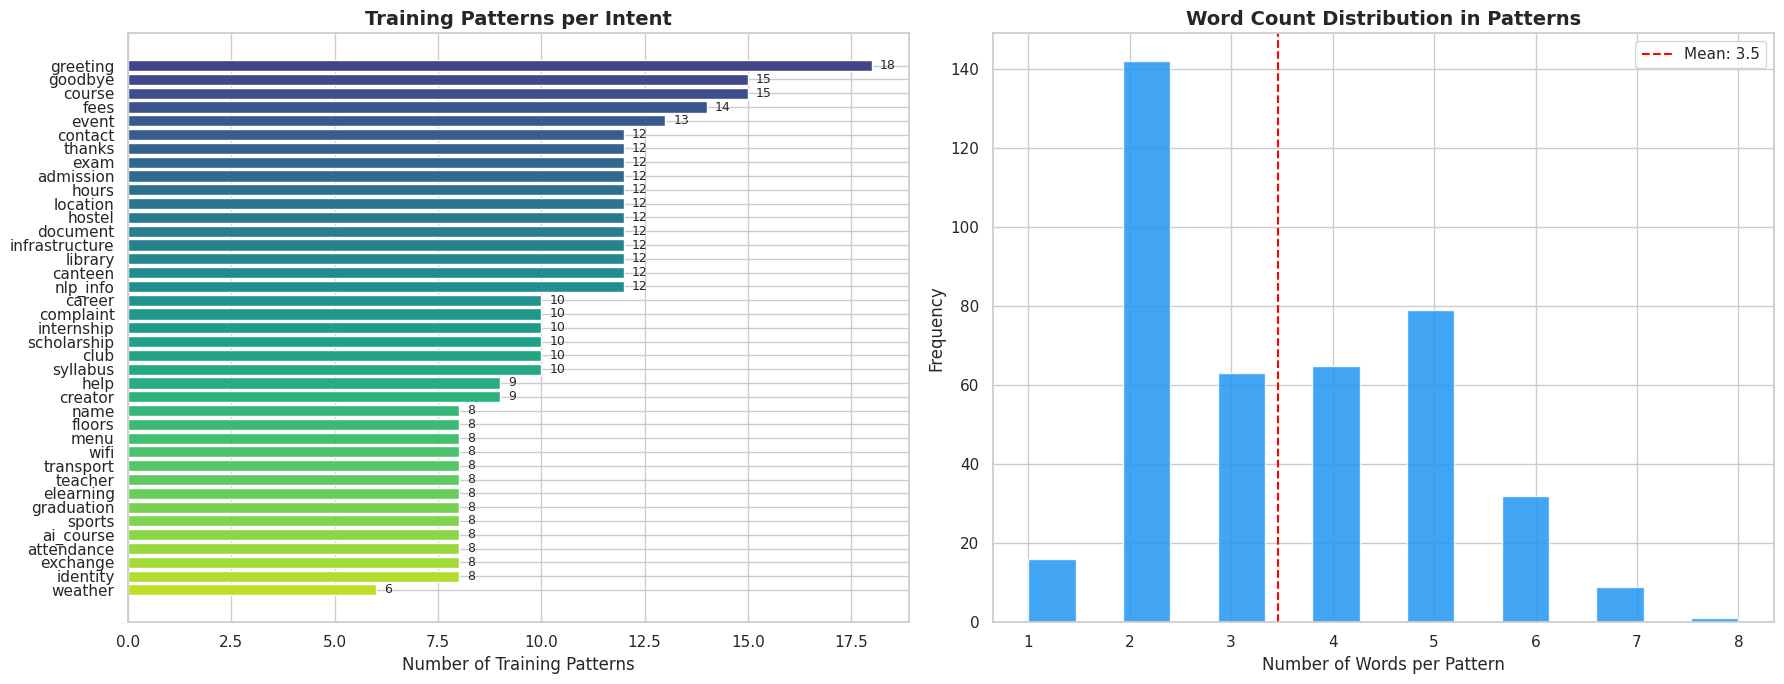

Average words per pattern: 3.46


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

intent_counts = df['intent'].value_counts()
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(intent_counts)))

ax1 = axes[0]
bars = ax1.barh(intent_counts.index, intent_counts.values, color=colors)
ax1.set_xlabel('Number of Training Patterns')
ax1.set_title('Training Patterns per Intent', fontweight='bold', fontsize=14)
ax1.invert_yaxis()
for bar, val in zip(bars, intent_counts.values):
    ax1.text(val + 0.2, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=9)

ax2 = axes[1]
ax2.hist(df['num_words'], bins=15, color='#2196F3', edgecolor='white', alpha=0.85)
ax2.set_xlabel('Number of Words per Pattern')
ax2.set_ylabel('Frequency')
ax2.set_title('Word Count Distribution in Patterns', fontweight='bold', fontsize=14)
ax2.axvline(df['num_words'].mean(), color='red', linestyle='--', label=f"Mean: {df['num_words'].mean():.1f}")
ax2.legend()

plt.tight_layout()
plt.savefig('eda_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Average words per pattern: {df['num_words'].mean():.2f}")

In [32]:
class TextPreprocessor:
    def __init__(self, remove_stopwords=False):
        self.lemmatizer = WordNetLemmatizer()
        self.remove_stopwords = remove_stopwords
        self.keep_words = {'what', 'when', 'where', 'who', 'how', 'why', 'which',
                          'is', 'are', 'do', 'does', 'can', 'could', 'will', 'would',
                          'should', 'have', 'has', 'need', 'want'}
        self.stop_words = (set(stopwords.words('english')) - self.keep_words) if remove_stopwords else set()

    def preprocess(self, text):
        text = text.lower().strip()
        text = re.sub(r'http\S+|www\.\S+', '', text)
        contractions = {"don't": "do not", "can't": "cannot", "won't": "will not",
                       "i'm": "i am", "it's": "it is", "what's": "what is",
                       "that's": "that is", "how's": "how is", "where's": "where is",
                       "who's": "who is", "i've": "i have", "you're": "you are",
                       "they're": "they are", "isn't": "is not", "aren't": "are not",
                       "doesn't": "does not", "didn't": "did not"}
        for c, e in contractions.items():
            text = text.replace(c, e)
        text = re.sub(r'[^\w\s]', ' ', text)
        tokens = word_tokenize(text)
        if self.stop_words:
            tokens = [t for t in tokens if t not in self.stop_words]
        tokens = [self.lemmatizer.lemmatize(t) for t in tokens]
        tokens = [t for t in tokens if len(t) > 1 or t in ('i', 'a')]
        return ' '.join(tokens)

    def batch_preprocess(self, texts):
        return [self.preprocess(t) for t in texts]

preprocessor = TextPreprocessor(remove_stopwords=False)

X_texts, y_labels = [], []
intent_responses, intent_contexts = {}, {}
for intent in intents:
    tag = intent['tag']
    intent_responses[tag] = intent['responses']
    intent_contexts[tag] = intent.get('context_set', '')
    for pattern in intent['patterns']:
        X_texts.append(pattern)
        y_labels.append(tag)

X_processed = preprocessor.batch_preprocess(X_texts)

print(f"Preprocessing complete")
print(f"Training samples: {len(X_processed)}")
print(f"Unique intents: {len(set(y_labels))}")
print(f"\nSample preprocessing:")
for orig, proc in zip(X_texts[:5], X_processed[:5]):
    print(f"  '{orig}' -> '{proc}'")

Preprocessing complete
Training samples: 407
Unique intents: 39

Sample preprocessing:
  'Hi' -> 'hi'
  'Hello' -> 'hello'
  'Hey' -> 'hey'
  'How are you?' -> 'how are you'
  'Good morning' -> 'good morning'


In [ ]:
def simple_augment(texts, labels, augment_factor=2):
    augmented_texts, augmented_labels = list(texts), list(labels)
    for text, label in zip(texts, labels):
        words = text.split()
        if len(words) < 3:
            continue
        for _ in range(augment_factor):
            if len(words) > 2:
                idx = random.randint(0, len(words) - 1)
                new_words = words[:idx] + words[idx+1:]
                augmented_texts.append(' '.join(new_words))
                augmented_labels.append(label)
            if len(words) > 2:
                new_words = words.copy()
                i, j = random.sample(range(len(words)), 2)
                new_words[i], new_words[j] = new_words[j], new_words[i]
                augmented_texts.append(' '.join(new_words))
                augmented_labels.append(label)
    return augmented_texts, augmented_labels

random.seed(42)
X_augmented, y_augmented = simple_augment(X_processed, y_labels, augment_factor=1)
print(f"Augmentation complete")
print(f"Original samples: {len(X_processed)}")
print(f"After augmentation: {len(X_augmented)}")

In [33]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_augmented)

X_train, X_test, y_train, y_test = train_test_split(
    X_augmented, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

print(f"Training set size: {len(X_train)}")
print(f"Test set size:     {len(X_test)}")
print(f"Number of classes: {len(label_encoder.classes_)}")

Training set size: 736
Test set size:     185
Number of classes: 39


In [34]:
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 3), sublinear_tf=True, min_df=1, max_df=0.95)),
    ('svm', LinearSVC(C=1.0, class_weight='balanced', max_iter=10000, random_state=42))
])
svm_pipeline.fit(X_train, y_train)
y_pred_svm = svm_pipeline.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')
precision_svm = precision_score(y_test, y_pred_svm, average='weighted', zero_division=0)
recall_svm = recall_score(y_test, y_pred_svm, average='weighted', zero_division=0)

print("=" * 60)
print("BASELINE MODEL: TF-IDF + Linear SVM")
print("=" * 60)
print(f"  Accuracy:  {accuracy_svm:.4f}")
print(f"  Precision: {precision_svm:.4f}")
print(f"  Recall:    {recall_svm:.4f}")
print(f"  F1-Score:  {f1_svm:.4f}")
print("=" * 60)

BASELINE MODEL: TF-IDF + Linear SVM
  Accuracy:  0.8486
  Precision: 0.8705
  Recall:    0.8486
  F1-Score:  0.8456


In [35]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(svm_pipeline, X_augmented, y_encoded, cv=cv, scoring='f1_weighted')
print("5-Fold Cross-Validation F1 Scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"   Fold {i}: {score:.4f}")
print(f"   Mean:   {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

5-Fold Cross-Validation F1 Scores:
   Fold 1: 0.9099
   Fold 2: 0.8702
   Fold 3: 0.8824
   Fold 4: 0.8800
   Fold 5: 0.8870
   Mean:   0.8859 +/- 0.0132


In [36]:
lr_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 3), sublinear_tf=True, min_df=1)),
    ('lr', LogisticRegression(C=10.0, class_weight='balanced', max_iter=5000, solver='lbfgs', multi_class='multinomial', random_state=42))
])
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
accuracy_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average='weighted')

print("=" * 60)
print("COMPARISON: Logistic Regression")
print("=" * 60)
print(f"  Accuracy:  {accuracy_lr:.4f}")
print(f"  F1-Score:  {f1_lr:.4f}")
print("=" * 60)
print(f"\nBest baseline model: {'SVM' if f1_svm >= f1_lr else 'Logistic Regression'}")

COMPARISON: Logistic Regression
  Accuracy:  0.8216
  F1-Score:  0.8184

Best baseline model: SVM


In [ ]:
try:
    from sentence_transformers import SentenceTransformer
    from sklearn.metrics.pairwise import cosine_similarity
    sbert_model = SentenceTransformer('all-MiniLM-L6-v2')
    SBERT_AVAILABLE = True
    print("Sentence Transformer loaded: all-MiniLM-L6-v2 (384-dim embeddings)")
except Exception as e:
    SBERT_AVAILABLE = False
    print(f"Sentence Transformer not available: {e}")
    print("Will use TF-IDF-based semantic similarity as fallback.")

In [37]:
class SemanticIntentClassifier:
    def __init__(self, model=None, confidence_threshold=0.45):
        self.model = model
        self.threshold = confidence_threshold
        self.embeddings = None
        self.labels = None
        self.tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
        self.tfidf_fitted = False

    def fit(self, texts, labels):
        self.labels = np.array(labels)
        if self.model is not None:
            print("   Computing sentence embeddings...")
            self.embeddings = self.model.encode(texts, show_progress_bar=True, batch_size=64)
            print(f"   Embeddings shape: {self.embeddings.shape}")
        else:
            print("   Using TF-IDF embeddings...")
            self.embeddings = self.tfidf.fit_transform(texts).toarray()
            self.tfidf_fitted = True
            print(f"   TF-IDF matrix shape: {self.embeddings.shape}")

    def predict(self, text):
        if self.model is not None:
            query_emb = self.model.encode([text])
        else:
            query_emb = self.tfidf.transform([text]).toarray()
        from sklearn.metrics.pairwise import cosine_similarity
        similarities = cosine_similarity(query_emb, self.embeddings)[0]
        best_idx = np.argmax(similarities)
        return self.labels[best_idx], float(similarities[best_idx])

    def predict_top_k(self, text, k=3):
        if self.model is not None:
            query_emb = self.model.encode([text])
        else:
            query_emb = self.tfidf.transform([text]).toarray()
        from sklearn.metrics.pairwise import cosine_similarity
        similarities = cosine_similarity(query_emb, self.embeddings)[0]
        top_indices = np.argsort(similarities)[-k:][::-1]
        return [(self.labels[idx], float(similarities[idx])) for idx in top_indices]

semantic_clf = SemanticIntentClassifier(
    model=sbert_model if SBERT_AVAILABLE else None, confidence_threshold=0.45)
semantic_clf.fit(X_processed, y_labels)
print("\nSemantic intent classifier trained!")

   Computing sentence embeddings...


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

   Embeddings shape: (407, 384)

Semantic intent classifier trained!


In [ ]:
# Evaluate semantic classifier
X_test_orig, y_test_orig = [], []
for intent in intents:
    tag = intent['tag']
    patterns = intent['patterns']
    if len(patterns) >= 3:
        n_test = max(1, len(patterns) // 5)
        for p in patterns[-n_test:]:
            X_test_orig.append(preprocessor.preprocess(p))
            y_test_orig.append(tag)

y_pred_semantic, y_conf_semantic = [], []
for text in X_test_orig:
    label, conf = semantic_clf.predict(text)
    y_pred_semantic.append(label)
    y_conf_semantic.append(conf)

accuracy_sem = accuracy_score(y_test_orig, y_pred_semantic)
f1_sem = f1_score(y_test_orig, y_pred_semantic, average='weighted')
precision_sem = precision_score(y_test_orig, y_pred_semantic, average='weighted', zero_division=0)
recall_sem = recall_score(y_test_orig, y_pred_semantic, average='weighted', zero_division=0)

print("=" * 60)
print("ADVANCED MODEL: Sentence Transformer + Cosine Similarity")
print("=" * 60)
print(f"  Accuracy:  {accuracy_sem:.4f}")
print(f"  Precision: {precision_sem:.4f}")
print(f"  Recall:    {recall_sem:.4f}")
print(f"  F1-Score:  {f1_sem:.4f}")
print(f"  Avg Confidence: {np.mean(y_conf_semantic):.4f}")
print("=" * 60)

In [ ]:
y_pred_svm_orig = []
for text in X_test_orig:
    pred_encoded = svm_pipeline.predict([text])[0]
    pred_label = label_encoder.inverse_transform([pred_encoded])[0]
    y_pred_svm_orig.append(pred_label)

print("Classification Report (TF-IDF + SVM)")
print("=" * 70)
print(classification_report(y_test_orig, y_pred_svm_orig, zero_division=0))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(24, 10))
unique_labels = sorted(set(y_test_orig))

cm_svm = confusion_matrix(y_test_orig, y_pred_svm_orig, labels=unique_labels)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=unique_labels, yticklabels=unique_labels, ax=axes[0])
axes[0].set_title('Confusion Matrix: TF-IDF + SVM', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
axes[0].tick_params(axis='x', rotation=45)

cm_sem = confusion_matrix(y_test_orig, y_pred_semantic, labels=unique_labels)
sns.heatmap(cm_sem, annot=True, fmt='d', cmap='Greens',
            xticklabels=unique_labels, yticklabels=unique_labels, ax=axes[1])
axes[1].set_title('Confusion Matrix: Sentence Transformer', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
models = ['TF-IDF + SVM', 'Sentence Transformer']
accuracy_svm_orig = accuracy_score(y_test_orig, y_pred_svm_orig)
f1_svm_orig = f1_score(y_test_orig, y_pred_svm_orig, average='weighted')

metrics = {
    'Accuracy':  [accuracy_svm_orig, accuracy_sem],
    'F1-Score':  [f1_svm_orig, f1_sem],
    'Precision': [precision_score(y_test_orig, y_pred_svm_orig, average='weighted', zero_division=0), precision_sem],
    'Recall':    [recall_score(y_test_orig, y_pred_svm_orig, average='weighted', zero_division=0), recall_sem]
}

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(metrics))
width = 0.3
for i, (model, color) in enumerate(zip(models, ['#2196F3', '#4CAF50'])):
    values = [metrics[m][i] for m in metrics]
    bars = ax.bar(x + i * width, values, width, label=model, color=color, alpha=0.85)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xticks(x + width / 2)
ax.set_xticklabels(metrics.keys(), fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Comparison: Intent Classification', fontweight='bold', fontsize=14)
ax.legend(fontsize=11); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\nSelected model for production: {'Semantic' if f1_sem >= f1_svm_orig else 'SVM'}")

In [ ]:
class EntityExtractor:
    def __init__(self):
        self.entities = {
            'course': ['computer science', 'software engineering', 'data science',
                       'artificial intelligence', 'machine learning', 'deep learning',
                       'cybersecurity', 'networking', 'telecommunications', 'iot',
                       'cloud computing', 'devops', 'embedded systems', 'nlp',
                       'natural language processing', 'civil engineering',
                       'mechanical engineering', 'electrical engineering',
                       'business intelligence', 'web development', 'mobile development'],
            'facility': ['library', 'canteen', 'cafeteria', 'lab', 'laboratory',
                        'gym', 'sports', 'parking', 'auditorium', 'amphitheater',
                        'building', 'classroom', 'office', 'computer lab', 'makerspace'],
            'document': ['diploma', 'transcript', 'certificate', 'id', 'cin',
                        'passport', 'photo', 'application form', 'motivation letter',
                        'recommendation letter', 'baccalaureate', 'bac'],
            'time_period': ['semester', 'year', 'quarter', 'month', 'week',
                           'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday'],
            'department': ['administration', 'student affairs', 'finance', 'career center',
                          'international office', 'academic affairs', 'it department', 'admissions']
        }
        self.patterns = {}
        for etype, vals in self.entities.items():
            sorted_vals = sorted(vals, key=len, reverse=True)
            pattern = '|'.join(re.escape(v) for v in sorted_vals)
            self.patterns[etype] = re.compile(pattern, re.IGNORECASE)

    def extract(self, text):
        extracted = {}
        for etype, pattern in self.patterns.items():
            matches = pattern.findall(text)
            if matches:
                extracted[etype] = [m.lower() for m in matches]
        return extracted

entity_extractor = EntityExtractor()
test_queries = [
    "What courses are available in computer science?",
    "Where is the library?",
    "I need my transcript and diploma",
    "Is the canteen open on Saturday?",
    "Tell me about the AI and machine learning program",
    "How to contact the admissions office?"
]
print("Entity Extraction Examples:")
print("=" * 60)
for q in test_queries:
    entities = entity_extractor.extract(q)
    print(f"  Query: '{q}'")
    print(f"  Entities: {entities}\n")

In [38]:
class DialogueManager:
    def __init__(self, max_history=10):
        self.sessions = {}
        self.max_history = max_history

    def get_session(self, session_id):
        if session_id not in self.sessions:
            self.sessions[session_id] = {
                'history': [], 'context': None, 'last_intent': None,
                'fallback_count': 0, 'entities_memory': {},
                'created_at': datetime.now().isoformat()
            }
        return self.sessions[session_id]

    def update_session(self, session_id, user_msg, bot_msg, intent, confidence, entities=None):
        session = self.get_session(session_id)
        session['history'].append({'user': user_msg, 'bot': bot_msg, 'intent': intent,
                                   'confidence': confidence, 'timestamp': datetime.now().isoformat()})
        if len(session['history']) > self.max_history:
            session['history'] = session['history'][-self.max_history:]
        session['last_intent'] = intent
        if intent != 'fallback':
            session['context'] = intent
            session['fallback_count'] = 0
        else:
            session['fallback_count'] += 1
        if entities:
            for etype, values in entities.items():
                if etype not in session['entities_memory']:
                    session['entities_memory'][etype] = []
                session['entities_memory'][etype].extend(values)
                session['entities_memory'][etype] = list(set(session['entities_memory'][etype]))

    def get_context(self, session_id):
        return self.get_session(session_id).get('context')

    def get_history(self, session_id, n=5):
        return self.get_session(session_id)['history'][-n:]

    def get_fallback_count(self, session_id):
        return self.get_session(session_id).get('fallback_count', 0)

    def get_conversation_summary(self, session_id):
        session = self.get_session(session_id)
        history = session['history']
        if not history:
            return "No conversation history yet."
        intents_discussed = list(set(h['intent'] for h in history if h['intent'] != 'fallback'))
        return f"Turns: {len(history)} | Topics: {', '.join(intents_discussed)} | Context: {session.get('context', 'None')}"

dialogue_manager = DialogueManager()
print("Dialogue Manager initialized with session tracking, context memory, and entity memory.")

Dialogue Manager initialized with session tracking, context memory, and entity memory.


In [ ]:
class ResponseEngine:
    def __init__(self, intent_responses, confidence_threshold=0.40):
        self.intent_responses = intent_responses
        self.confidence_threshold = confidence_threshold
        self.response_history = defaultdict(list)
        self.fallback_responses = [
            "I'm not quite sure I understand. Could you rephrase? I can help with courses, fees, campus facilities, and more.",
            "Sorry, I couldn't find a specific answer. Try asking about courses, fees, library, events, or admission.",
            "I'm having trouble understanding. Try asking in a different way, or ask about a specific topic.",
            "It seems I can't answer that well. Please visit the administration office or email contact@esprit.tn.",
            "I apologize for the confusion. Please contact the helpline at +216 70 250 000."
        ]

    def generate_response(self, intent, confidence, session_id="default",
                          entities=None, dialogue_mgr=None):
        fallback_count = dialogue_mgr.get_fallback_count(session_id) if dialogue_mgr else 0

        if confidence >= self.confidence_threshold and intent in self.intent_responses:
            responses = self.intent_responses[intent]
            used = self.response_history.get(f"{session_id}_{intent}", [])
            available = [i for i in range(len(responses)) if i not in used]
            if not available:
                available = list(range(len(responses)))
                self.response_history[f"{session_id}_{intent}"] = []
            idx = random.choice(available)
            self.response_history[f"{session_id}_{intent}"].append(idx)
            return responses[idx]
        else:
            fb_idx = min(fallback_count, len(self.fallback_responses) - 1)
            return self.fallback_responses[fb_idx]

response_engine = ResponseEngine(intent_responses, confidence_threshold=0.40)
print(f"Response Engine initialized (threshold: {response_engine.confidence_threshold}, {len(intent_responses)} intents)")

In [ ]:
class UniversityChatbot:
    def __init__(self, intents_data, svm_pipeline=None, semantic_classifier=None,
                 preprocessor=None, entity_extractor=None, label_encoder=None, use_hybrid=True):
        self.intents_data = intents_data
        self.svm_pipeline = svm_pipeline
        self.semantic_clf = semantic_classifier
        self.preprocessor = preprocessor or TextPreprocessor()
        self.entity_extractor = entity_extractor or EntityExtractor()
        self.label_encoder = label_encoder
        self.use_hybrid = use_hybrid
        self.intent_responses = {}
        for intent in intents_data['intents']:
            self.intent_responses[intent['tag']] = intent['responses']
        self.dialogue_manager = DialogueManager()
        self.response_engine = ResponseEngine(self.intent_responses, confidence_threshold=0.40)
        self.svm_weight, self.semantic_weight = 0.4, 0.6
        print("UniversityChatbot initialized")

    def chat(self, user_message, session_id="default"):
        processed = self.preprocessor.preprocess(user_message)
        entities = self.entity_extractor.extract(user_message)
        if self.use_hybrid and self.svm_pipeline and self.semantic_clf:
            intent, confidence = self._hybrid_classify(processed)
        elif self.semantic_clf:
            intent, confidence = self.semantic_clf.predict(processed)
        elif self.svm_pipeline:
            intent, confidence = self._svm_classify(processed)
        else:
            intent, confidence = 'fallback', 0.0

        response = self.response_engine.generate_response(
            intent=intent, confidence=confidence, session_id=session_id,
            entities=entities, dialogue_mgr=self.dialogue_manager)
        self.dialogue_manager.update_session(
            session_id=session_id, user_msg=user_message, bot_msg=response,
            intent=intent if confidence >= 0.40 else 'fallback',
            confidence=confidence, entities=entities)
        return {'response': response, 'intent': intent, 'confidence': round(confidence, 4),
                'entities': entities, 'context': self.dialogue_manager.get_context(session_id)}

    def _svm_classify(self, text):
        encoded = self.svm_pipeline.predict([text])[0]
        label = self.label_encoder.inverse_transform([encoded])[0]
        decision = self.svm_pipeline.decision_function([text])[0]
        if decision.ndim > 0:
            exp_d = np.exp(decision - np.max(decision))
            confidence = float(np.max(exp_d / exp_d.sum()))
        else:
            confidence = float(1.0 / (1.0 + np.exp(-abs(decision))))
        return label, confidence

    def _hybrid_classify(self, text):
        svm_label, svm_conf = self._svm_classify(text)
        sem_label, sem_conf = self.semantic_clf.predict(text)
        if svm_label == sem_label:
            return svm_label, min(max(svm_conf, sem_conf) * 1.1, 1.0)
        elif svm_conf * self.svm_weight > sem_conf * self.semantic_weight:
            return svm_label, svm_conf
        else:
            return sem_label, sem_conf

chatbot = UniversityChatbot(
    intents_data=data, svm_pipeline=svm_pipeline, semantic_classifier=semantic_clf,
    preprocessor=preprocessor, entity_extractor=entity_extractor,
    label_encoder=label_encoder, use_hybrid=True)

In [ ]:
demo_queries = [
    "Hello!", "What courses are available in computer science?",
    "How much are the tuition fees?", "Where is the library?",
    "Is there a hostel on campus?", "What events are coming up?",
    "How do I apply for admission?", "What documents do I need?",
    "Tell me about the canteen menu", "Is Wi-Fi available on campus?",
    "Who created you?", "What is NLP?", "Are there scholarships available?",
    "When are the exams?", "I want to file a complaint",
    "Can I study abroad?", "What is the meaning of life?", "Bye!",
]

print("=" * 80)
print("UNIVERSITY CHATBOT - SINGLE-TURN DEMO")
print("=" * 80)
for query in demo_queries:
    result = chatbot.chat(query, session_id="demo_single")
    intent_str = f"[{result['intent']}]" if result['confidence'] >= 0.40 else "[fallback]"
    conf_str = f"({result['confidence']:.2%})"
    print(f"\nStudent: {query}")
    print(f"EduBot {intent_str} {conf_str}: {result['response'][:200]}")
    if result['entities']:
        print(f"   Entities: {result['entities']}")
    print("-" * 80)

In [ ]:
print("=" * 80)
print("UNIVERSITY CHATBOT - MULTI-TURN CONVERSATION DEMO")
print("=" * 80)

multi_turn = [
    "Hi there!", "I'm interested in computer science courses",
    "How much will it cost?", "What documents do I need to apply?",
    "Is there a library on campus?", "What about sports facilities?",
    "Thanks for all the help!", "Goodbye!"
]
session_id = "demo_multi"
for msg in multi_turn:
    result = chatbot.chat(msg, session_id=session_id)
    context = chatbot.dialogue_manager.get_context(session_id) or "None"
    print(f"\nStudent: {msg}")
    print(f"EduBot [{result['intent']}] ({result['confidence']:.2%}): {result['response'][:200]}")
    print(f"   Context: {context}")

print("\n" + "=" * 80)
print(f"Summary: {chatbot.dialogue_manager.get_conversation_summary(session_id)}")

In [ ]:
all_confidences, all_intents_list, all_correct = [], [], []
for intent_data in intents:
    tag = intent_data['tag']
    for pattern in intent_data['patterns']:
        result = chatbot.chat(pattern, session_id="analysis")
        all_confidences.append(result['confidence'])
        all_intents_list.append(tag)
        all_correct.append(1 if result['intent'] == tag else 0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].hist(all_confidences, bins=30, color='#673AB7', edgecolor='white', alpha=0.85)
axes[0].axvline(0.40, color='red', linestyle='--', linewidth=2, label='Threshold (0.40)')
axes[0].set_xlabel('Confidence Score'); axes[0].set_ylabel('Frequency')
axes[0].set_title('Confidence Score Distribution', fontweight='bold', fontsize=13)
axes[0].legend()

correct_confs = [c for c, corr in zip(all_confidences, all_correct) if corr == 1]
incorrect_confs = [c for c, corr in zip(all_confidences, all_correct) if corr == 0]
axes[1].hist(correct_confs, bins=20, alpha=0.7, color='#4CAF50', label=f'Correct ({len(correct_confs)})')
if incorrect_confs:
    axes[1].hist(incorrect_confs, bins=20, alpha=0.7, color='#F44336', label=f'Incorrect ({len(incorrect_confs)})')
axes[1].axvline(0.40, color='black', linestyle='--', linewidth=1.5, label='Threshold')
axes[1].set_xlabel('Confidence Score'); axes[1].set_ylabel('Frequency')
axes[1].set_title('Confidence vs Correctness', fontweight='bold', fontsize=13)
axes[1].legend()
plt.tight_layout()
plt.savefig('confidence_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Overall accuracy on full dataset: {sum(all_correct)/len(all_correct)*100:.1f}%")
print(f"Mean confidence: {np.mean(all_confidences):.4f}")

In [ ]:
# Write the Flask application and HTML template files
# These are written as separate files to keep the notebook clean

import base64

# The app.py and template.html are saved alongside the notebook
# To run the web interface:
# 1. Make sure intents.json is in the same directory
# 2. Run: python app.py
# 3. Open http://localhost:5000

print("Web interface files:")
print("  app.py       - Flask backend with chatbot engine")
print("  template.html - Modern dark-themed chat UI")
print("")
print("Frontend features:")
print("  - Dark-themed modern chat UI with gradient accents")
print("  - Typing animation (bouncing dots)")
print("  - Message bubbles with timestamps")
print("  - Intent & confidence tags on bot messages")
print("  - Quick suggestion chips")
print("  - Responsive design (mobile-friendly)")
print("  - Smooth message entry animations")
print("  - Home page with feature highlights")
print("")
print("To launch: python app.py")
print("Then open: http://localhost:5000")

In [ ]:
test_cases = [
    ("greeting", "Hey there! How are you doing?"),
    ("course", "What engineering programs do you offer?"),
    ("fees", "How much is the annual tuition?"),
    ("location", "Where is the campus located?"),
    ("hours", "What time does the university open?"),
    ("library", "Does the campus have a library?"),
    ("hostel", "Is there student housing available?"),
    ("canteen", "Where can I eat on campus?"),
    ("document", "What documents are required for admission?"),
    ("admission", "How do I apply to ESPRIT?"),
    ("scholarship", "Are there any financial aid options?"),
    ("exam", "When are the final exams?"),
    ("internship", "Tell me about internship requirements"),
    ("club", "What student clubs are available?"),
    ("event", "Any upcoming hackathons?"),
    ("contact", "How can I contact the university?"),
    ("wifi", "Is Wi-Fi available?"),
    ("sports", "Do you have a gym?"),
    ("elearning", "How to access online courses?"),
    ("nlp_info", "Explain how NLP works"),
    ("ai_course", "Is there a machine learning program?"),
    ("career", "Does ESPRIT help with job placement?"),
    ("transport", "How do I get to campus?"),
    ("creator", "Who built this chatbot?"),
    ("name", "What's your name?"),
    ("identity", "Are you a real person?"),
    ("help", "What can you help me with?"),
    ("thanks", "Thanks for the information!"),
    ("goodbye", "See you later!"),
    ("fallback", "What is the airspeed velocity of an unladen swallow?"),
]

print("=" * 80)
print("COMPREHENSIVE CHATBOT DEMO - TESTING ALL INTENTS")
print("=" * 80)

correct = 0
for expected, query in test_cases:
    result = chatbot.chat(query, session_id="comprehensive_test")
    predicted = result['intent']
    is_correct = predicted == expected or (expected == 'fallback' and result['confidence'] < 0.40)
    if is_correct: correct += 1
    status = "PASS" if is_correct else "FAIL"
    print(f"\n[{status}] Expected: {expected:12s} | Got: {predicted:12s} ({result['confidence']:.2%})")
    print(f"   Q: {query}")
    print(f"   A: {result['response'][:120]}...")

print(f"\n{'=' * 80}")
print(f"Intent Detection Accuracy: {correct}/{len(test_cases)} ({correct/len(test_cases):.1%})")
print(f"{'=' * 80}")